# SPI–SPI proof of concept — p90, 2026-10-14

Fresh extraction with the current 283-SPI catalogue (pyspi computation r9). The figures compare ten generator classes, then four CML regimes, and finally individual SPI–SPI coordinates that distinguish pairs of classes. These embeddings illustrate organisation; they do not establish invariance to channel count or recording length.

In [1]:
from pathlib import Path
import sys, json, os
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from research.proof.p90.refresh_proof_figures import (load_bank, embeddings, rank_features, plot_embedding, plot_discriminative)
BANK = Path(os.environ.get('PROOF_REFRESH_BANK', ROOT / 'data/proof/refresh-261014/features.npz'))
OUT = Path(os.environ.get('PROOF_REFRESH_OUTPUT', ROOT / 'results/proof/refresh-261014'))
bank = load_bank(BANK, expected_spis=283)
OUT.mkdir(parents=True, exist_ok=True)
print(f"{len(bank['y'])} datasets; {len(bank['spi_order'])} SPIs; {bank['X_sym'].shape[1]:,} coordinates")

1080 datasets; 283 SPIs; 39,903 coordinates


We retain the original proof's feature definition: symmetrise each interaction matrix, take its unique off-diagonal channel pairs, and calculate Pearson correlation between each pair of SPI vectors. Directed information is discarded in this particular view. This produces $\binom{283}{2}=39\,903$ possible coordinates.

Each class has ten instances at every combination of $M\in\{8,16,32\}$ and $T\in\{500,1000,2000\}$. Each panel fits its own unsupervised preprocessing: retain coordinates finite in at least 95% of its datasets, median-impute missing entries, discard near-constant coordinates and centre without variance scaling. PCA provides the linear view. UMAP and t-SNE use the same first 50 PCs: UMAP has 25 neighbours, min_dist=0.25 and spectral initialisation; t-SNE has perplexity 30, PCA initialisation, automatic learning rate, early exaggeration 12 and 1,500 iterations. Both use seed 260924; their neighbourhood parameters are not numerically equivalent. Centring is a design choice, not something mathematically forced by the bounded coordinate range. No class labels enter these fits.

The three VAR models use a fixed ring with literal (self, total-neighbour) coefficients (0.70,0.20), (0.20,0.20), (0.20,0.70). Each neighbour receives half the total weight. These isolate changes in self-dependence and neighbour coupling against the same middle reference. Their spectral radii are 0.90, 0.40 and 0.90; no stability rescaling is applied. Innovation standard deviation is 0.1 and burn-in is 100 steps. This intentionally replaces the old pre-normalisation VAR weights; other generators retain their existing settings.

In [2]:
coords = embeddings(bank, OUT, protocol_path=ROOT / 'research/proof/p90/configs/analysis/proof-refresh-261014.yaml')
ranked = rank_features(bank, OUT)

/Users/wedi0306/Code/mts-spi-study-cluster/.venv/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Inter-class view. Colours identify classes and remain fixed in subsequent panels. Point size encodes M=8,16,32. Axis coordinates from separate fits are not directly comparable.

PCA is the primary view: its axes have linear loadings and explained variance. This makes them inspectable, not automatically identifiable with physical character; nuisance variation and redundant coordinates can dominate them. t-SNE is the nonlinear companion; UMAP remains an optional comparison below. UMAP and t-SNE axes have no intrinsic meaning; distances between clusters and cluster areas are sensitive to the method and settings. Fixed seeds do not guarantee identical layouts across platforms. Agreement is a visual robustness check, not independent validation. See the original [t-SNE](https://www.jmlr.org/papers/v9/vandermaaten08a.html) and [UMAP](https://arxiv.org/abs/1802.03426) papers, and the [initialisation comparison](https://www.nature.com/articles/s41587-020-00809-z).

The coordinate archive also stores PC1/PC2 loadings, feature indices and centring values for each panel, so the linear axes can be traced back to their SPI pairs.

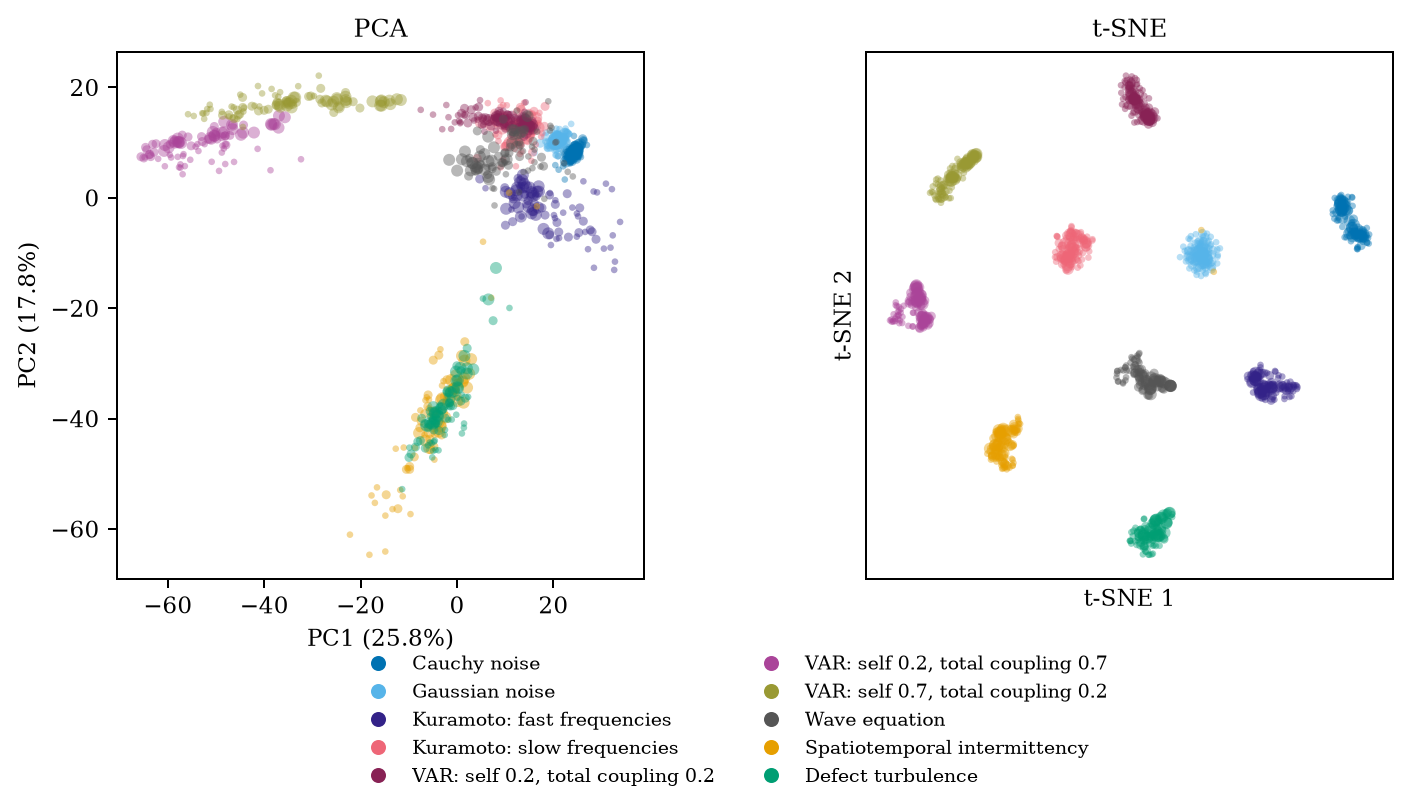

In [3]:
fig = plot_embedding(bank, coords, 'inter', OUT)
plt.show()

Within-CML view: frozen chaos, spatiotemporal intermittency, defect turbulence and fully developed turbulence. The same two bridge classes use the same datasets and colours as the inter-class view.

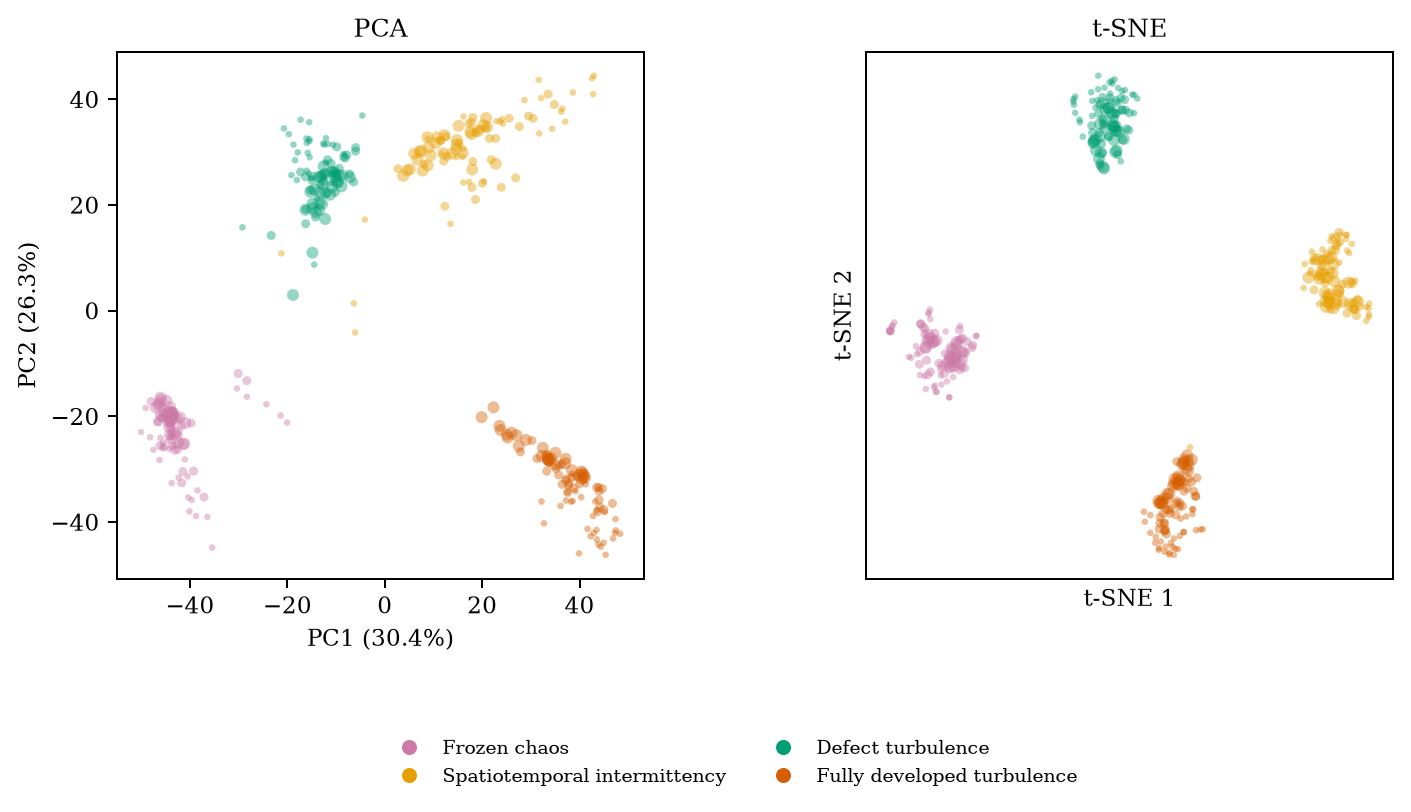

In [4]:
fig = plot_embedding(bank, coords, 'cml', OUT)
plt.show()

Discriminative coordinates. For each class pair, select the SPI pair with greatest training AUC separation using instances 0–5 across all nine M/T cells. The rainclouds display instances 6–9 only (up to 36 datasets/class; undefined coordinate values are omitted), with the training orientation fixed when calculating display AUC. Dots are datasets; density shapes are descriptive; short bars mark medians. This limits feature-selection optimism within this rerun, but remains exploratory because these generator families and earlier outcomes have already been inspected. No best-feature significance claim is made.

Each panel is square and boxed. Its y-limits cover the compared classes jointly, with padding; repeated uses of one SPI coordinate share limits, while different coordinates have different limits. Read the numerical ticks when comparing panels: visible separation on a tight scale is not a large absolute change in z. All finite display observations remain visible.

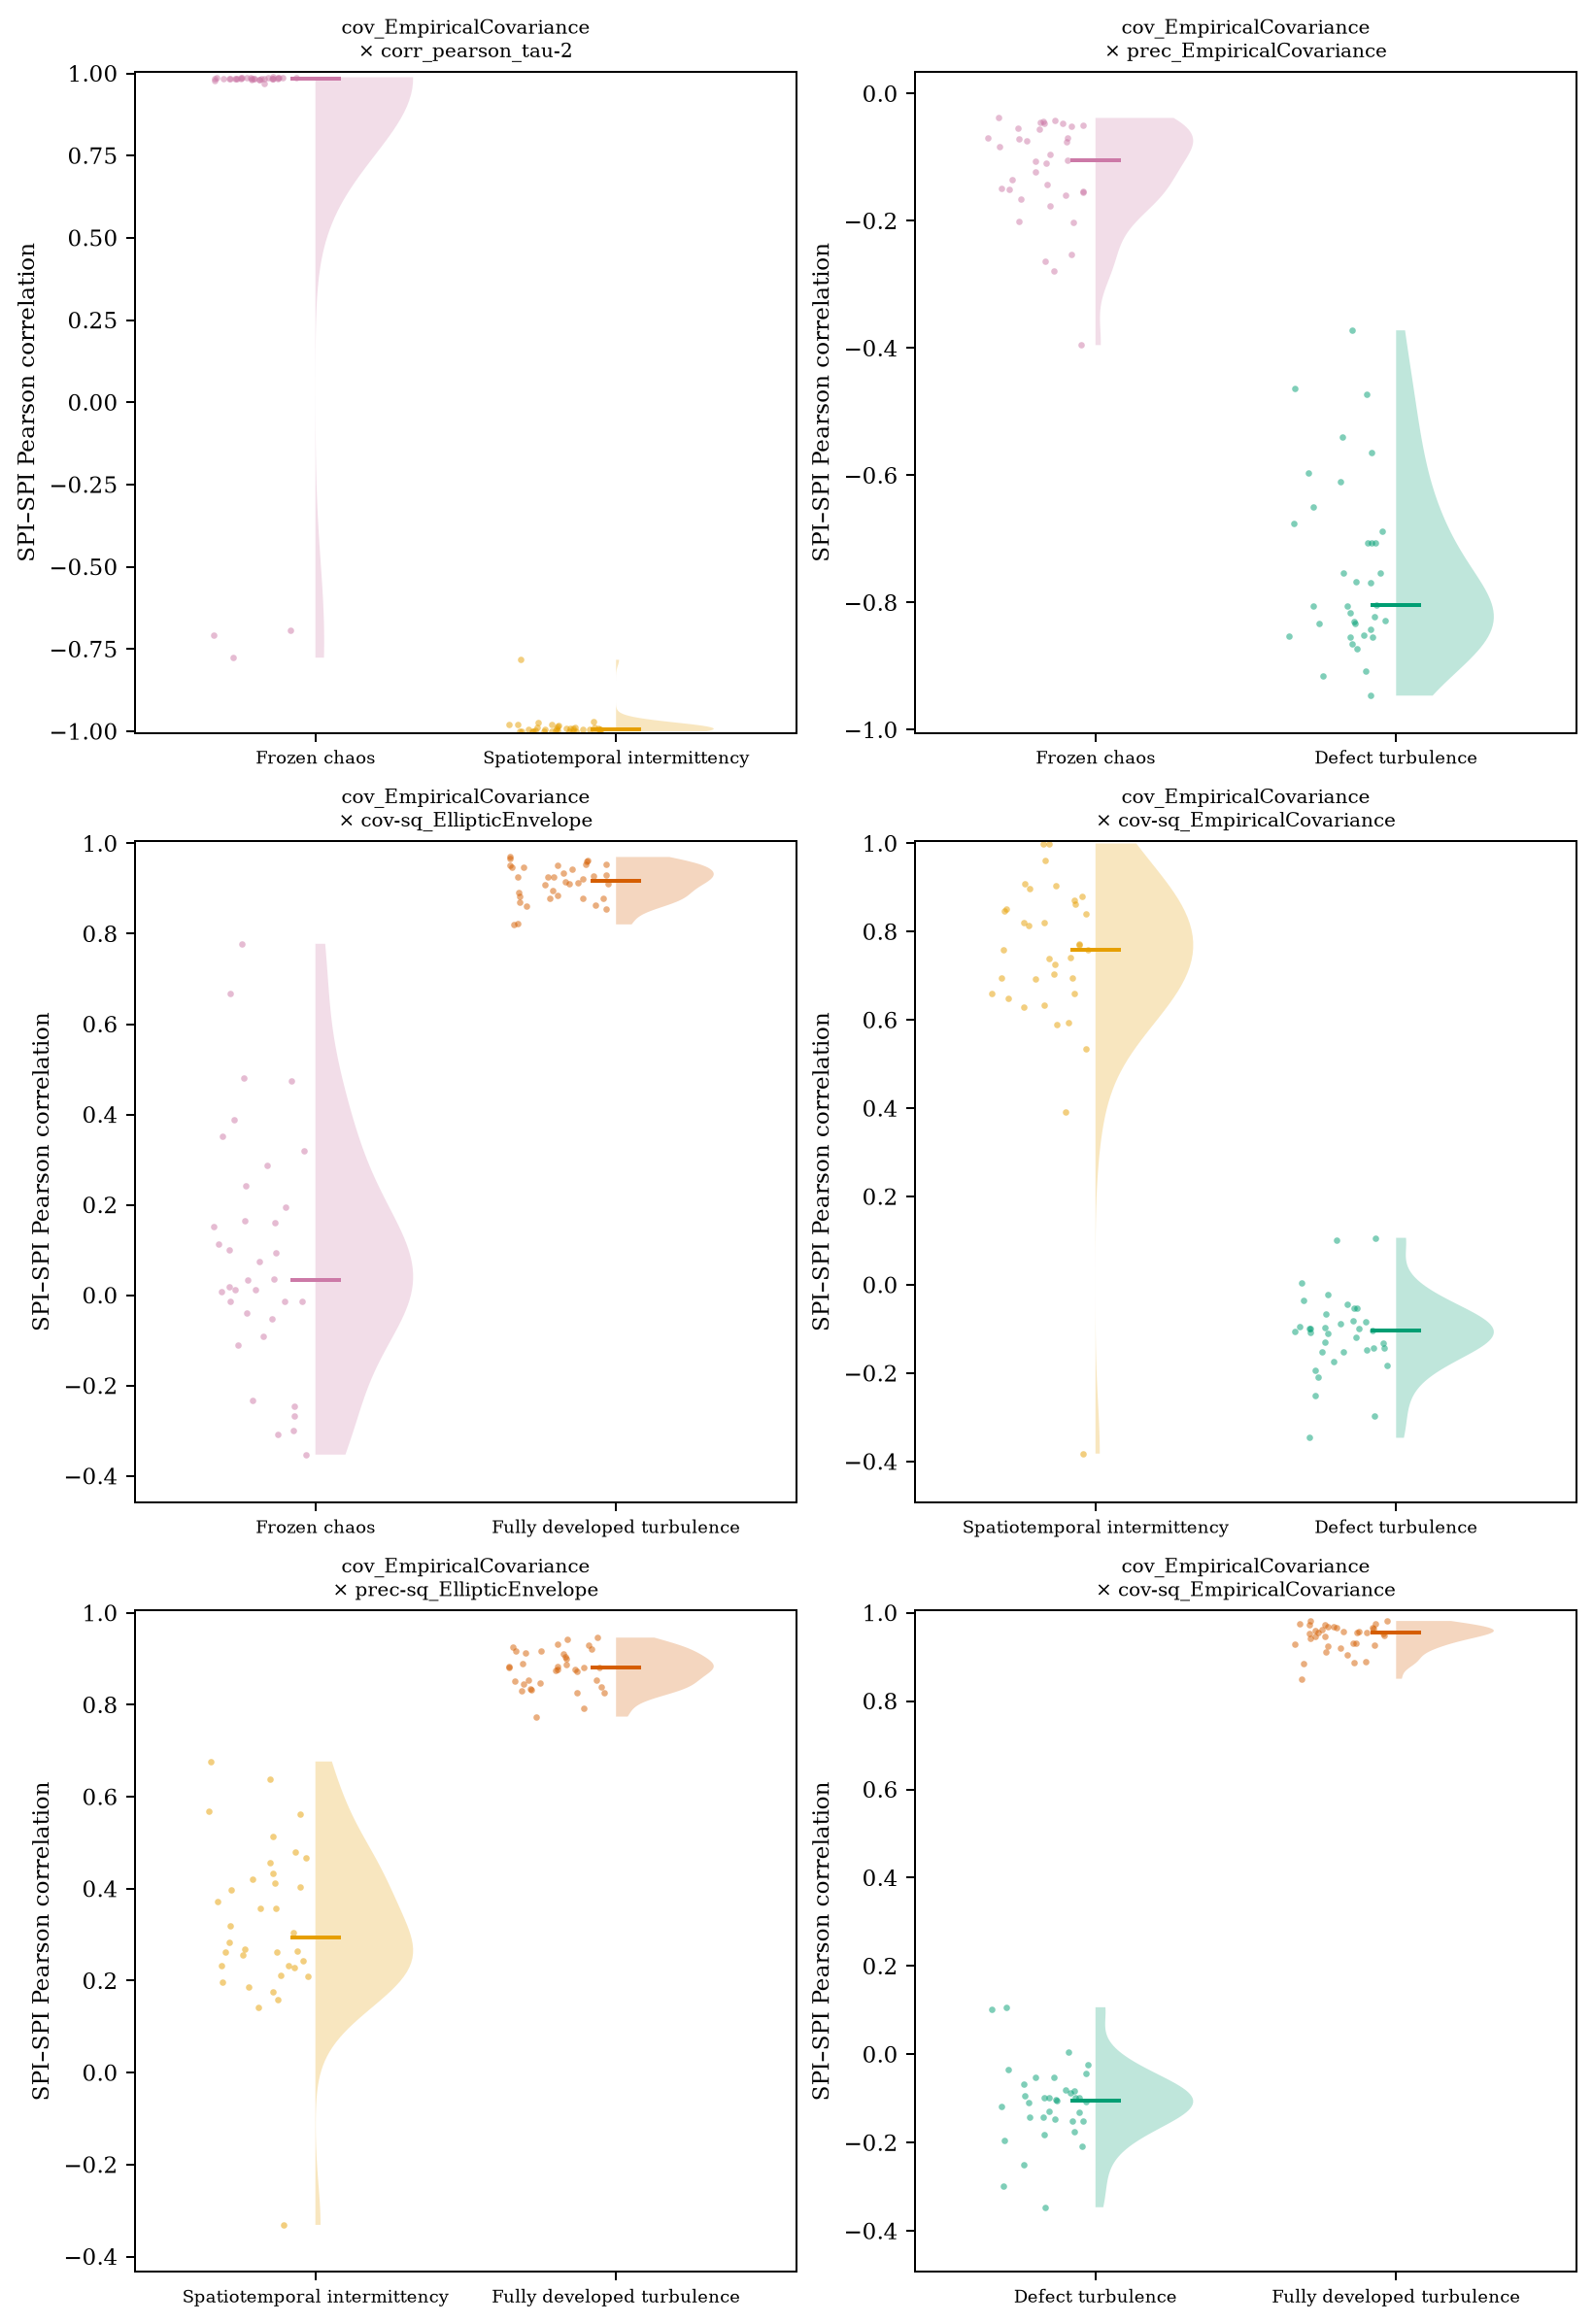

In [5]:
fig = plot_discriminative(bank, ranked, 'cml', OUT)
plt.show()

Coarse contrasts use the same selection rule for Gaussian versus Cauchy noise and all three VAR class pairs.

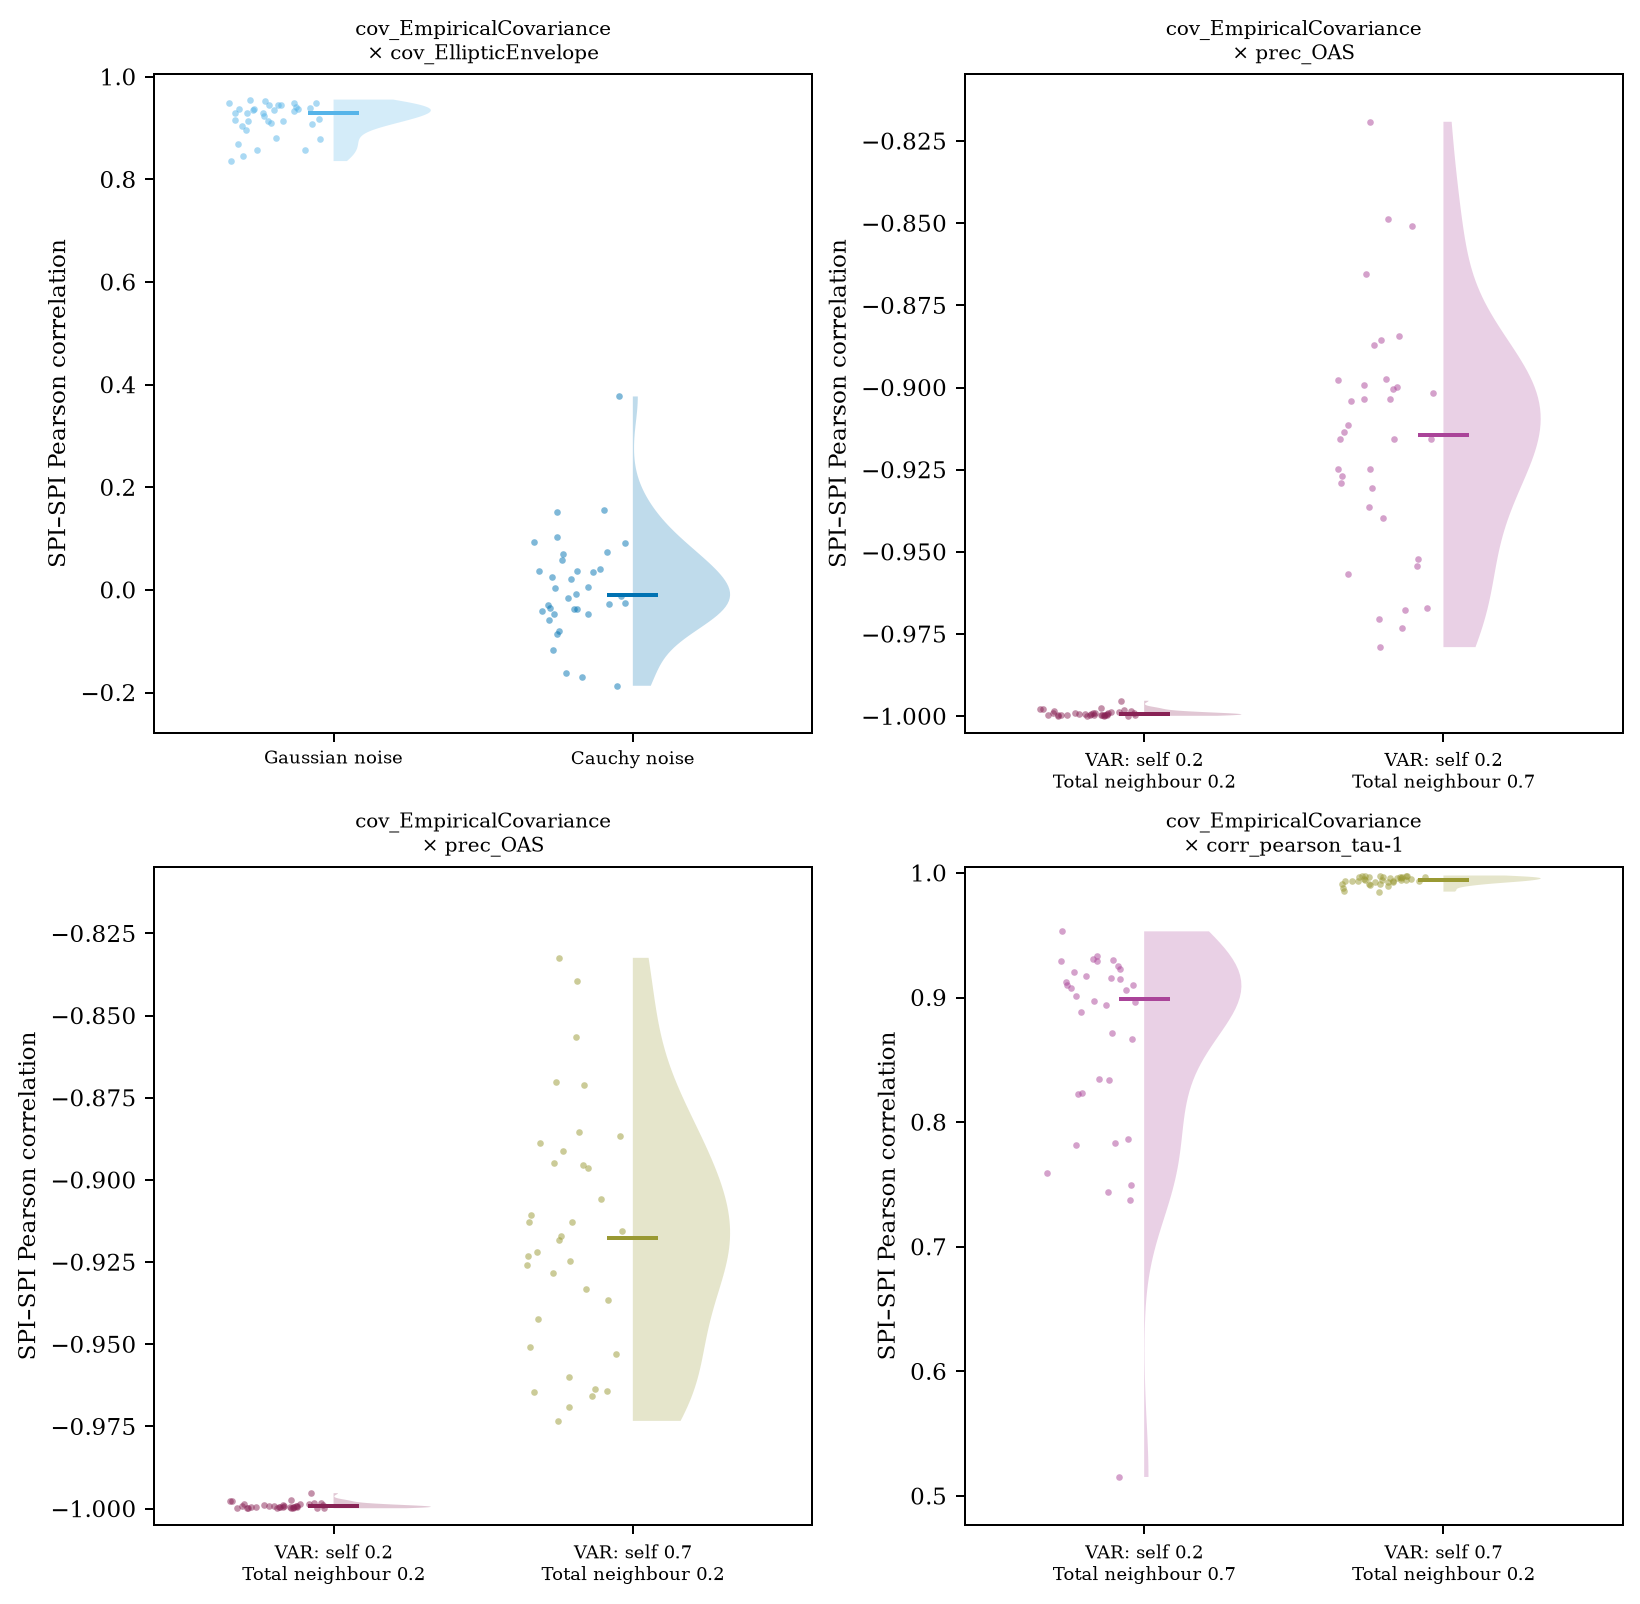

In [6]:
fig = plot_discriminative(bank, ranked, 'coarse', OUT)
plt.show()

Generation and analysis settings: `research/proof/p90/configs/analysis/proof-refresh-261014.yaml`. Current pyspi fixes its stochastic estimator seeds. Undefined SPI values remain masked; no historical r7 matrices enter this run. Figures are saved as SVG and PNG.

Optional UMAP comparison, using the same saved preprocessing and fitted coordinates. Enable the flag to display it; the main figures prioritise PCA and t-SNE.

In [7]:
SHOW_UMAP = False
if SHOW_UMAP:
    for panel in ['inter', 'cml']:
        fig = plot_embedding(bank, coords, panel, OUT, methods=['umap'])
        plt.show()